# 05 - Trends 2020-2026: MACS admissions and all subjects

Inputs: Free University admitted lists 2020-2024 (extracted from NAEC PDFs: scaled scores only,
`data/processed/admitted_036_all.csv`), admitted lists 2025-2026 (xlsx, raw + scaled), equating tables,
NAEC statistical analysis 2022-2026 (`data/processed/statanalysis.csv`), program-choice counts.

For 2020-2024 the raw math score of each admit is recovered from the scaled score with a linear
scaled-vs-equated fit at the top of the scale (src/scores.py `top_linear_g`); on 2025-2026, where raw
scores are published, this recovers 100% of raw scores >= 46 exactly.

In [1]:
from common import *
from load import load_equating, load_admissions, subject_code
from scores import top_linear_g, scaled_to_raw_top

eq = load_equating()
old = pd.read_csv(ROOT / "data/processed/admitted_036_all.csv", dtype={"prog_code": str, "exam_id": str})
old["el1_code"] = old.el1.map(lambda s: subject_code(s) if isinstance(s, str) else np.nan)
MACS_CODE = {2020: "03601044", 2021: "03601044", 2022: "03601044", 2023: "03601044", 2024: "03601044",
             2025: "03601054", 2026: "03601044"}

frames = []
for y in range(2020, 2027):
    if y <= 2024:
        d = old[old.year == y].copy()
        e = eq[(eq.year == y) & (eq.subject == "MATH")]
        mth = d[d.el1_code == "MATH"]
        a_, b_, share = top_linear_g(mth.el1_sc.values, e)
        rec = scaled_to_raw_top(d.loc[d.el1_code == "MATH", "el1_sc"].values, e, a_, b_)
        d.loc[d.el1_code == "MATH", "el1_raw"] = rec.raw.values
        d.loc[d.el1_code == "MATH", "raw_err"] = rec.err.values
        d["b_slope"] = b_
    else:
        d = load_admissions(y)
        d = d[d.uni_code == "036"].copy()
        d["b_slope"] = np.nan
    frames.append(d.assign(year=y))
fu = pd.concat(frames, ignore_index=True)

## 1. MACS competitive-score weights by year (least squares on admitted students; residual must be 0)

In [2]:
rows = []
for y in range(2020, 2027):
    m = fu[(fu.year == y) & (fu.prog_code == MACS_CODE[y]) & (fu.el1_code == "MATH")]
    X = m[["geo_sc", "fl_sc", "el1_sc"]].values
    w, *_ = np.linalg.lstsq(X, m.comp.values, rcond=None)
    rows.append({"year": y, "w_geo": w[0].round(3), "w_fl": w[1].round(3), "w_math": w[2].round(3),
                 "max_resid": np.abs(X @ w - m.comp.values).max().round(3), "n": len(m)})
W = pd.DataFrame(rows).set_index("year")
W

,w_geo,w_fl,w_math,max_resid,n
year,,,,,
2020,1.0,3.0,8.0,0.0,50
2021,1.0,3.0,8.0,0.0,50
2022,1.0,3.0,8.0,0.0,53
2023,1.0,3.0,8.0,0.0,54
2024,1.0,3.0,8.0,0.0,63
2025,1.0,1.0,10.0,0.0,57
2026,1.0,1.0,10.0,0.0,57


## 2. MACS admissions 2020-2026, in raw math points

In [3]:
rows = []
for y in range(2020, 2027):
    m = fu[(fu.year == y) & (fu.prog_code == MACS_CODE[y]) & (fu.el1_code == "MATH")]
    e = eq[(eq.year == y) & (eq.subject == "MATH")]
    b_ = m.b_slope.iloc[0] if y <= 2024 else top_linear_g(fu[(fu.year == y) & (fu.el1_code == "MATH")].el1_sc.values, e)[1]
    pt = W.loc[y, "w_math"] * b_  # one raw math point at the top, in competitive-score points
    nat = eq[(eq.year == y) & (eq.subject == "MATH")]
    M = nat.max_raw.iloc[0]
    rows.append({
        "year": y, "math_max": M, "weights (geo, fl, math)": f"{W.loc[y,'w_geo']:.0f}, {W.loc[y,'w_fl']:.0f}, {W.loc[y,'w_math']:.0f}",
        "admitted_math_route": len(m), "math_raw_min": m.el1_raw.min(), "math_raw_median": m.el1_raw.median(),
        "pct_admits_math_ge_49": 100 * (m.el1_raw >= 49).mean(), "pct_admits_math_at_max": 100 * (m.el1_raw == M).mean(),
        "pct_admits_math_top3": 100 * (m.el1_raw >= M - 2).mean(),
        "comp_range": m.comp.max() - m.comp.min(), "one_math_point_in_comp": pt,
        "comp_range_in_math_points": (m.comp.max() - m.comp.min()) / pt,
        "national_math_ge_49": nat[nat.raw >= 49].n.sum(), "national_math_at_max": nat[nat.raw == M].n.sum(),
        "national_math_takers": nat.n.sum(),
        "max_raw_recovery_err_macs": m.raw_err.max() if y <= 2024 else 0.0,
    })
T = pd.DataFrame(rows)
T.to_csv(OUT / "t05_macs_by_year.csv", index=False)
T.round(2).T

,0,1,2,3,4,5,6
year,2020,2021,2022,2023,2024,2025,2026
math_max,59,51,51,51,51,51,51
"weights (geo, fl, math)","1, 3, 8","1, 3, 8","1, 3, 8","1, 3, 8","1, 3, 8","1, 1, 10","1, 1, 10"
admitted_math_route,50,50,53,54,63,57,57
math_raw_min,55.0,45.0,47.0,49.0,45.0,49.0,48.0
math_raw_median,57.0,49.0,49.0,50.0,50.0,50.0,50.0
pct_admits_math_ge_49,100.0,52.0,66.04,100.0,60.32,100.0,98.25
pct_admits_math_at_max,14.0,14.0,15.09,35.19,26.98,42.11,42.11
pct_admits_math_top3,78.0,52.0,66.04,100.0,60.32,100.0,98.25
comp_range,41.1,60.0,42.1,29.5,56.7,34.7,28.4


## 3. Demand for MACS (applicants listing it as 1st choice; both routes together)

In [4]:
dem = pd.DataFrame([
    {"year": 2020, "first_choice": 289, "listed_anywhere": 553, "source": "applications_2020.xlsx"},
    {"year": 2024, "first_choice": 274, "listed_anywhere": 655, "source": "choices_2024.xlsx"},
    {"year": 2026, "first_choice": 171, "listed_anywhere": 688, "source": "choices_2026.xlsx"},
])
seats = fu[fu.prog.str.contains(r"კომპიუტერული მეცნიერებ\w* და მათემატიკა", regex=True, na=False)].groupby("year").size()
dem["admitted_both_routes"] = dem.year.map(seats)
dem["first_choice_per_seat"] = dem.first_choice / dem.admitted_both_routes
dem.to_csv(OUT / "t05_macs_demand.csv", index=False)
dem

,year,first_choice,listed_anywhere,source,admitted_both_routes,first_choice_per_seat
0,2020,289,553,applications_2020.xlsx,50,5.780000
1,2024,274,655,choices_2024.xlsx,64,4.281250
2,2026,171,688,choices_2026.xlsx,64,2.671875


## 4. All subjects 2022-2026 (NAEC statistical analysis): how often is the maximum reached?
`pct_at_max` = % of test-takers with the maximum possible score (0 if nobody reached it).

In [5]:
sa = pd.read_csv(ROOT / "data/processed/statanalysis.csv")
sa["subject"] = sa.subject_ka.map(subject_code)
sa = sa[sa.n >= 200]
sa["n_at_max"] = np.where(sa.top_obtained >= sa.max_score, sa.n_top_obtained, 0)
agg = (sa.groupby(["subject", "year"])
       .agg(max_score=("max_score", "first"), N=("n", "sum"), n_at_max=("n_at_max", "sum"),
            mean_difficulty=("mean_difficulty", lambda s: np.average(s, weights=sa.loc[s.index, "n"])))
       .reset_index())
agg["pct_at_max"] = 100 * agg.n_at_max / agg.N
agg.to_csv(OUT / "t05_all_subjects_at_max.csv", index=False)
agg.pivot(index="subject", columns="year", values="pct_at_max").round(2)

year,2022,2023,2024,2025,2026
subject,,,,,
ART,NaN,0.00,0.00,0.00,0.00
BIO,0.09,0.00,0.00,0.03,0.03
CHEM,0.33,0.31,0.27,0.34,0.30
CIV,0.20,0.00,0.00,0.00,0.04
ENG,0.58,1.76,2.91,3.37,3.61
GAT_AM,0.00,0.00,0.00,0.00,0.00
GAT_AZ,0.00,0.00,0.00,0.00,0.00
GEO,0.17,0.19,0.21,0.37,0.35
GEOG,0.00,0.00,0.00,0.00,0.00


In [6]:
agg.pivot(index="subject", columns="year", values="mean_difficulty").round(1)

year,2022,2023,2024,2025,2026
subject,,,,,
ART,NaN,54.5,53.9,56.6,56.6
BIO,58.7,53.0,50.6,49.4,43.6
CHEM,54.9,50.4,47.7,51.0,47.4
CIV,52.6,51.0,49.8,48.7,52.7
ENG,59.9,65.2,66.3,68.1,71.4
GAT_AM,41.8,43.1,48.7,48.3,46.0
GAT_AZ,37.4,38.6,41.4,44.2,43.3
GEO,63.8,63.2,62.3,65.1,65.5
GEOG,36.2,47.5,48.8,39.6,38.6


## Figure 7 - Mathematics and MACS, 2020-2026

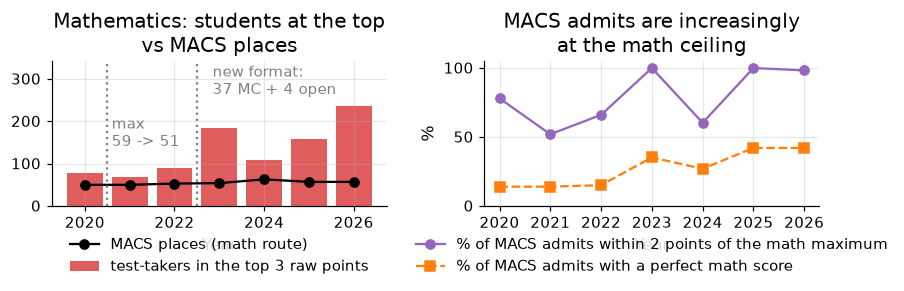

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8.4, 2.9))
ax = axes[0]
top3 = eq[(eq.subject == "MATH") & (eq.raw >= eq.max_raw - 2)].groupby("year").n.sum()
ax.bar(top3.index, top3.values, color="tab:red", alpha=0.75, label="test-takers in the top 3 raw points")
ax.plot(T.year, T.admitted_math_route, "ko-", label="MACS places (math route)")
ax.axvline(2022.5, color="grey", ls=":")
ax.text(2022.85, top3.max() * 1.42, "new format:\n37 MC + 4 open", fontsize=9.5,
        color="grey", va="top", ha="left")
ax.axvline(2020.5, color="grey", ls=":")
ax.text(2020.6, top3.max() * 0.9, "max\n59 -> 51", fontsize=9.5, color="grey", va="top")
ax.set_ylim(0, top3.max() * 1.45)
ax.set_title("Mathematics: students at the top\nvs MACS places")
ax.set_xlabel("Year")
ax.legend(framealpha=0.85, edgecolor="none", loc="upper center", bbox_to_anchor=(0.5, -0.13))
ax = axes[1]
ax.plot(T.year, T.pct_admits_math_top3, "o-", color="tab:purple", label="% of MACS admits within 2 points of the math maximum")
ax.plot(T.year, T.pct_admits_math_at_max, "s--", color="tab:orange", label="% of MACS admits with a perfect math score")
ax.set_ylim(0, 105)
ax.set_xlabel("Year")
ax.set_ylabel("%")
ax.set_title("MACS admits are increasingly\nat the math ceiling")
ax.legend(framealpha=0.85, edgecolor="none", loc="upper center", bbox_to_anchor=(0.5, -0.13))
fig.tight_layout()
savefig(fig, "fig07_trends")